In [1]:
import pandas as pd

In [2]:
athlete_events = pd.read_csv('athlete_events.csv')
noc_regions = pd.read_csv('noc_regions.csv')
df = athlete_events.merge(noc_regions, on='NOC', how='inner')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region,notes
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,China,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,China,NaN
2,602,Abudoureheman,M,22.0,182.0,75.0,China,CHN,2000 Summer,2000,Summer,Sydney,Boxing,Boxing Men's Middleweight,NaN,China,NaN
3,1463,Ai Linuer,M,25.0,160.0,62.0,China,CHN,2004 Summer,2004,Summer,Athina,Wrestling,"Wrestling Men's Lightweight, Greco-Roman",NaN,China,NaN
4,1464,Ai Yanhan,F,14.0,168.0,54.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 200 metres Freestyle,NaN,China,NaN


In [3]:
rio_swimming = df[(df.Games=='2016 Summer') & (df.Sport=='Swimming')]
rio_swimming.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region,notes
4,1464,Ai Yanhan,F,14.0,168.0,54.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 200 metres Freestyle,NaN,China,NaN
5,1464,Ai Yanhan,F,14.0,168.0,54.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 4 x 200 metres Freestyle Relay,NaN,China,NaN
107,18006,Cao Yue,F,20.0,178.0,72.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 400 metres Freestyle,NaN,China,NaN
175,20214,Chen Jie,F,21.0,177.0,65.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 200 metres Backstroke,NaN,China,NaN
261,20299,Chen Xinyi,F,18.0,177.0,60.0,China,CHN,2016 Summer,2016,Summer,Rio de Janeiro,Swimming,Swimming Women's 100 metres Butterfly,NaN,China,NaN


In [4]:
rio_swimming_noc = rio_swimming.loc[:, ['NOC', 'Event', 'Medal']].dropna().drop_duplicates()
rio_swimming_noc

,NOC,Event,Medal
623,CHN,Swimming Women's 100 metres Backstroke,Bronze
2832,CHN,Swimming Women's 200 metres Breaststroke,Bronze
3042,CHN,Swimming Men's 200 metres Freestyle,Gold
3043,CHN,Swimming Men's 400 metres Freestyle,Silver
3486,CHN,Swimming Men's 200 metres Individual Medley,Bronze
...,...,...,...
204532,GBR,Swimming Women's 800 metres Freestyle,Silver
207049,GBR,Swimming Men's 4 x 200 metres Freestyle Relay,Silver
207051,GBR,Swimming Men's 4 x 100 metres Medley Relay,Silver
210821,GBR,Swimming Women's 200 metres Individual Medley,Silver


In [5]:
rio_swimming_noc['Gold'] = rio_swimming_noc['Medal'].map({'Gold': 'Gold'})
rio_swimming_noc['Silver'] = rio_swimming_noc['Medal'].map({'Silver': 'Silver'})
rio_swimming_noc['Bronze'] = rio_swimming_noc['Medal'].map({'Bronze': 'Bronze'})
rio_swimming_noc

,NOC,Event,Medal,Gold,Silver,Bronze
623,CHN,Swimming Women's 100 metres Backstroke,Bronze,NaN,NaN,Bronze
2832,CHN,Swimming Women's 200 metres Breaststroke,Bronze,NaN,NaN,Bronze
3042,CHN,Swimming Men's 200 metres Freestyle,Gold,Gold,NaN,NaN
3043,CHN,Swimming Men's 400 metres Freestyle,Silver,NaN,Silver,NaN
3486,CHN,Swimming Men's 200 metres Individual Medley,Bronze,NaN,NaN,Bronze
...,...,...,...,...,...,...
204532,GBR,Swimming Women's 800 metres Freestyle,Silver,NaN,Silver,NaN
207049,GBR,Swimming Men's 4 x 200 metres Freestyle Relay,Silver,NaN,Silver,NaN
207051,GBR,Swimming Men's 4 x 100 metres Medley Relay,Silver,NaN,Silver,NaN
210821,GBR,Swimming Women's 200 metres Individual Medley,Silver,NaN,Silver,NaN


In [7]:
rio_swimming_table_pie = rio_swimming_noc.loc[:, ['NOC', 'Medal']].groupby(['NOC']).count()
rio_swimming_table_pie

,Medal
NOC,
AUS,10
BEL,1
BLR,1
BRA,1
CAN,6
CHN,6
DEN,2
ESP,2
FRA,3


<AxesSubplot:ylabel='Medal'>

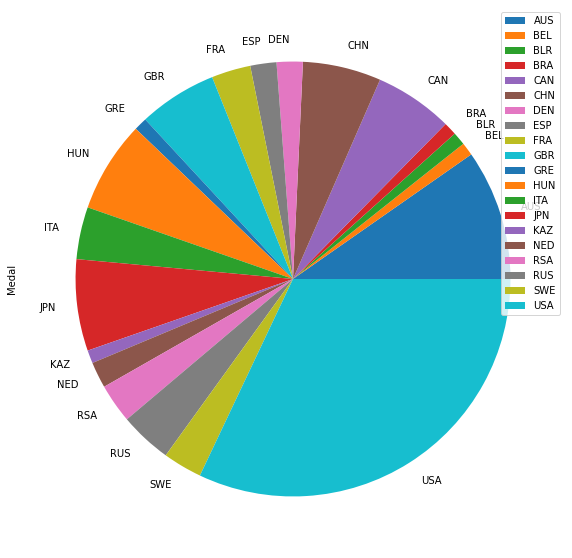

In [9]:
rio_swimming_table_pie.plot.pie(y='Medal', figsize=(11,10))

In [10]:
rio_swimming_noc['Medal_Count'] = rio_swimming_noc.groupby(['NOC'])['Medal'].transform('count')
rio_swimming_noc['Gold_Medal_Count'] = rio_swimming_noc.groupby(['NOC'])['Gold'].transform('count')
rio_swimming_noc['Silver_Medal_Count'] = rio_swimming_noc.groupby(['NOC'])['Silver'].transform('count')
rio_swimming_noc['Bronze_Medal_Count'] = rio_swimming_noc.groupby(['NOC'])['Bronze'].transform('count')
rio_swimming_noc

,NOC,Event,Medal,Gold,Silver,Bronze,Medal_Count,Gold_Medal_Count,Silver_Medal_Count,Bronze_Medal_Count
623,CHN,Swimming Women's 100 metres Backstroke,Bronze,NaN,NaN,Bronze,6,1,2,3
2832,CHN,Swimming Women's 200 metres Breaststroke,Bronze,NaN,NaN,Bronze,6,1,2,3
3042,CHN,Swimming Men's 200 metres Freestyle,Gold,Gold,NaN,NaN,6,1,2,3
3043,CHN,Swimming Men's 400 metres Freestyle,Silver,NaN,Silver,NaN,6,1,2,3
3486,CHN,Swimming Men's 200 metres Individual Medley,Bronze,NaN,NaN,Bronze,6,1,2,3
...,...,...,...,...,...,...,...,...,...,...
204532,GBR,Swimming Women's 800 metres Freestyle,Silver,NaN,Silver,NaN,6,1,5,0
207049,GBR,Swimming Men's 4 x 200 metres Freestyle Relay,Silver,NaN,Silver,NaN,6,1,5,0
207051,GBR,Swimming Men's 4 x 100 metres Medley Relay,Silver,NaN,Silver,NaN,6,1,5,0
210821,GBR,Swimming Women's 200 metres Individual Medley,Silver,NaN,Silver,NaN,6,1,5,0


In [23]:
rio_swimming_medal_table = rio_swimming_noc.loc[:, ['NOC', 'Medal_Count', 'Gold_Medal_Count', 'Silver_Medal_Count', 'Bronze_Medal_Count']].drop_duplicates().sort_values(by=['Gold_Medal_Count','Medal_Count'], ascending=False)
rio_swimming_medal_table

,NOC,Medal_Count,Gold_Medal_Count,Silver_Medal_Count,Bronze_Medal_Count
14646,USA,33,16,8,9
143438,AUS,10,3,4,3
112972,HUN,7,3,2,2
164683,JPN,7,2,2,3
13773,NED,2,2,0,0
623,CHN,6,1,2,3
133676,CAN,6,1,1,4
204531,GBR,6,1,5,0
75208,ITA,4,1,1,2
197154,SWE,3,1,1,1


<AxesSubplot:xlabel='NOC'>

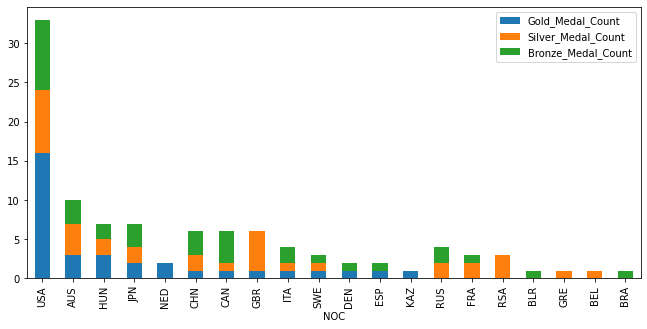

In [24]:
rio_swimming_medal_table.plot.bar(x='NOC', y=['Gold_Medal_Count', 'Silver_Medal_Count', 'Bronze_Medal_Count'], stacked=True, figsize=(11,5))

<AxesSubplot:xlabel='NOC'>

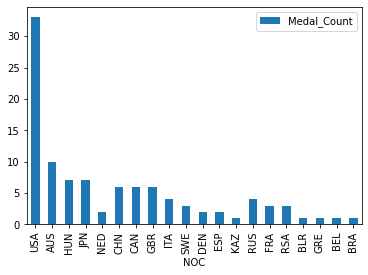

In [25]:
rio_swimming_medal_table.plot.bar(x='NOC', y='Medal_Count')

<AxesSubplot:xlabel='NOC'>

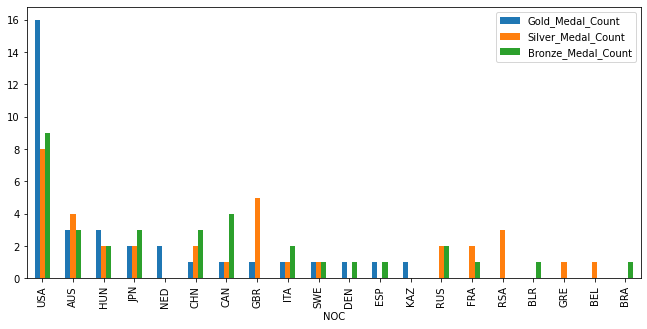

In [26]:
rio_swimming_medal_table.plot.bar(x='NOC', y=['Gold_Medal_Count', 'Silver_Medal_Count', 'Bronze_Medal_Count'], figsize=(11,5))